# 23CSE301 Machine Learning - Capstone Project
## Classification Track — FIFA WorldCup 2026
### Algorithm: Support Vector Classifier

---

**Standard Notebook Format**
| Section | Description |
|---------|-------------|
| Cell 2  | Imports & Setup |
| Cell 4  | Dataset Loading & Audit |
| Cell 6  | Exploratory Data Analysis (EDA) |
| Cell 8  | Data Preprocessing |
| Cell 10 | Model Training |
| Cell 12 | Model Evaluation |
| Cell 14 | Results & Conclusions |

---
## Section 1: Environment Setup & Library Imports

**Purpose**: Import computational libraries.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score
,confusion_matrix,classification_report,roc_auc_score)
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
print("All are OK")

All are OK


---
## Section 2: Dataset Loading & Audit

**Audit Requirements**: shape, dtypes, missing values, duplicates.

In [17]:
df = pd.read_csv("../../../data/classification/classification.csv")
# Subsample to 10000 rows for computational efficiency
df = df.sample(n=10000, random_state=RANDOM_STATE).reset_index(drop=True)

print("="*35)
print(f"Dataset shape: {df.shape}")
print(f"Columns: {len(df.columns)}")
print(f"\nData types:\n{df.dtypes.value_counts()}")
print(f"\nMissing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print("="*35)
print("="*40)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("="*40)

# Cap extreme outliers on skewed count features at 1st/99th percentiles
cap_cols = ['shots','tackles','defensive_actions','accelerations','decelerations']
for col in cap_cols:
    lower = df[col].quantile(0.01)
    upper = df[col].quantile(0.99)
    df[col] = df[col].clip(lower, upper)
    print(f"  Capped {col}: [{lower}, {upper}]")
print("="*40)

Dataset shape: (10000, 75)
Columns: 75

Data types:
int64      43
float64    18
str        14
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0
Missing values: 0
Duplicate rows: 0
  Capped shots: [0.0, 4.0]
  Capped tackles: [0.0, 6.0]
  Capped defensive_actions: [0.0, 14.0]
  Capped accelerations: [0.0, 33.0]
  Capped decelerations: [0.0, 29.0]


Missing values: 0
Duplicate rows: 0
  Capped shots: [0.0, 4.0]
  Capped tackles: [0.0, 6.0]
  Capped defensive_actions: [0.0, 14.0]
  Capped accelerations: [0.0, 33.0]
  Capped decelerations: [0.0, 29.0]


---
## Section 3: Exploratory Data Analysis (EDA)

**Visualizations**: Class distribution, feature distributions.

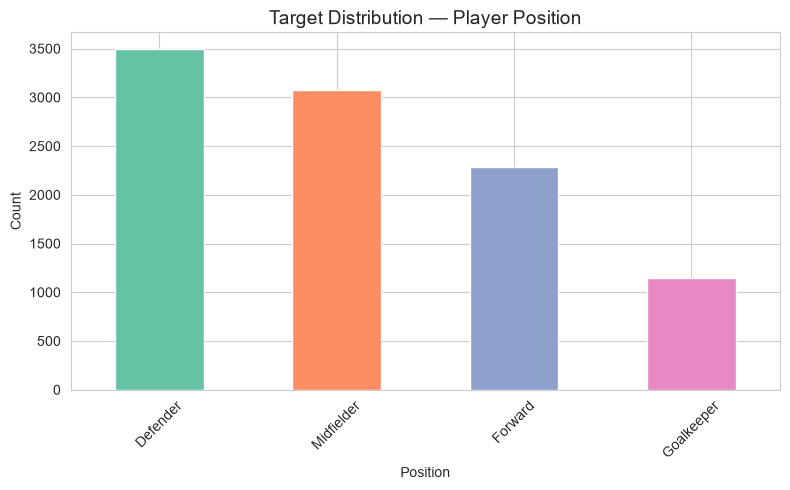

Class proportions:
position
Defender      0.3491
Forward       0.2284
Goalkeeper    0.1151
Midfielder    0.3074
Name: proportion, dtype: float64


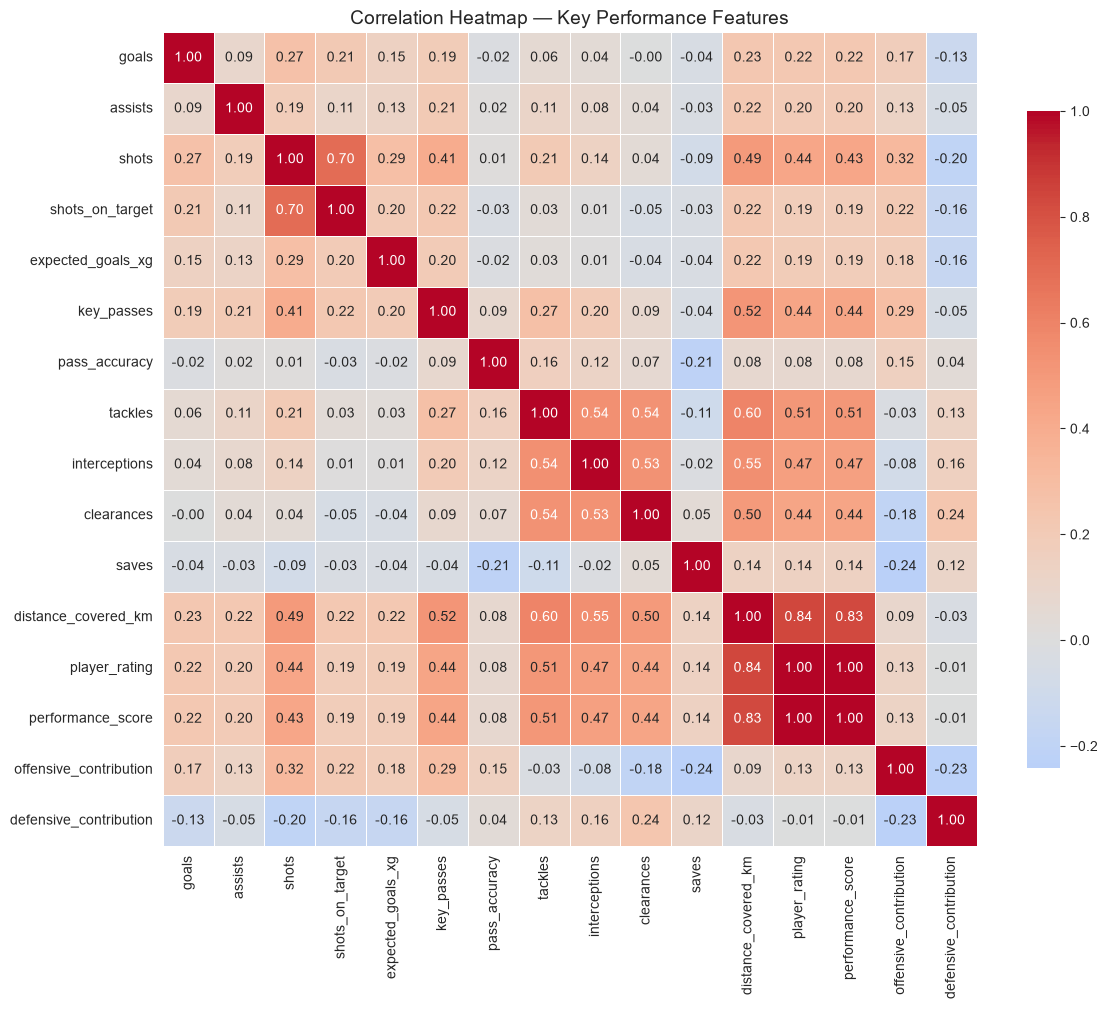

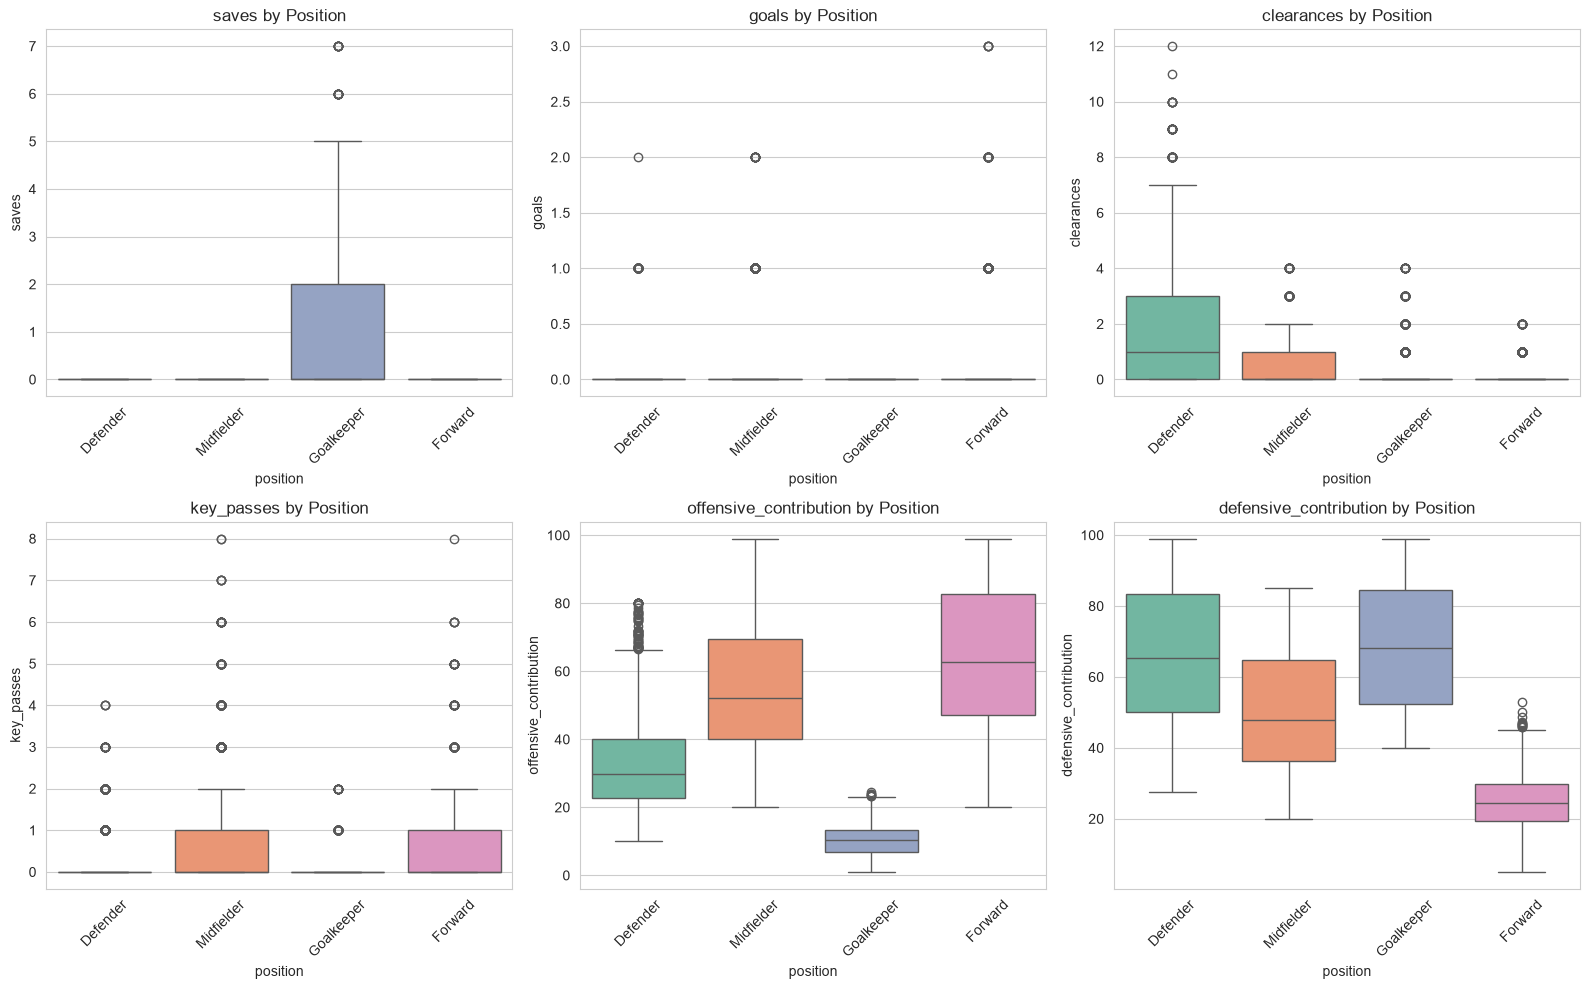

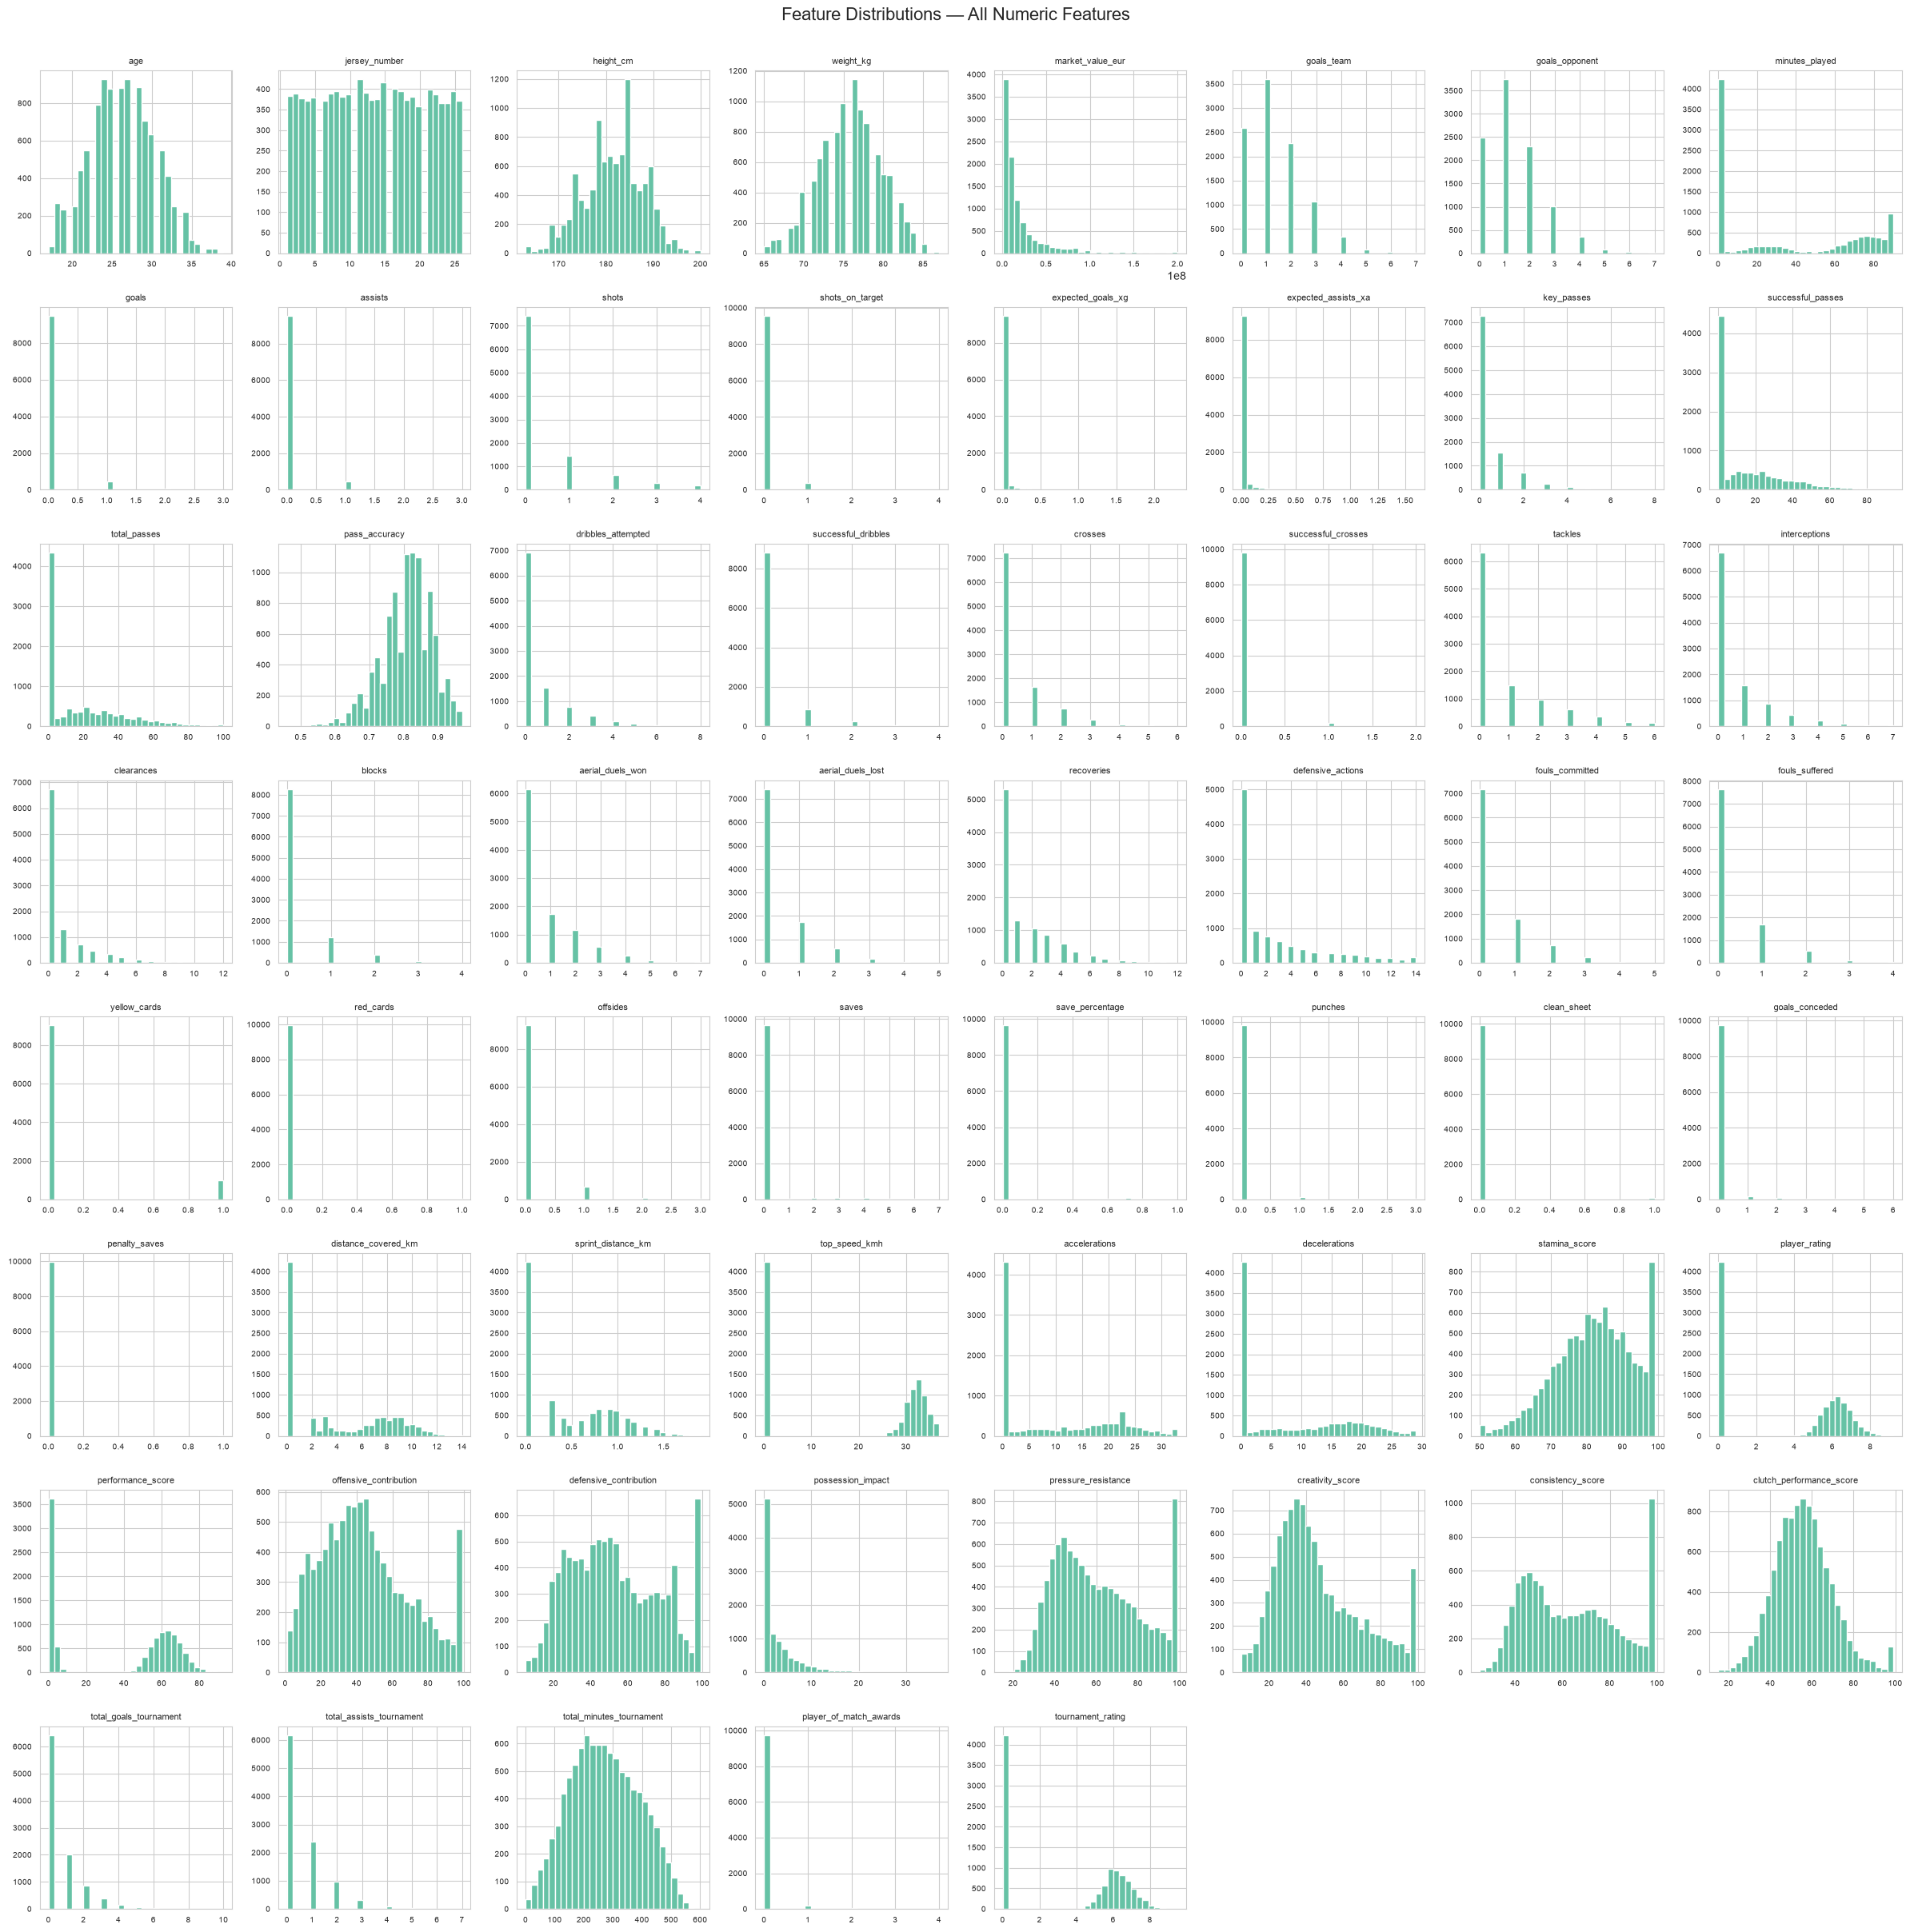

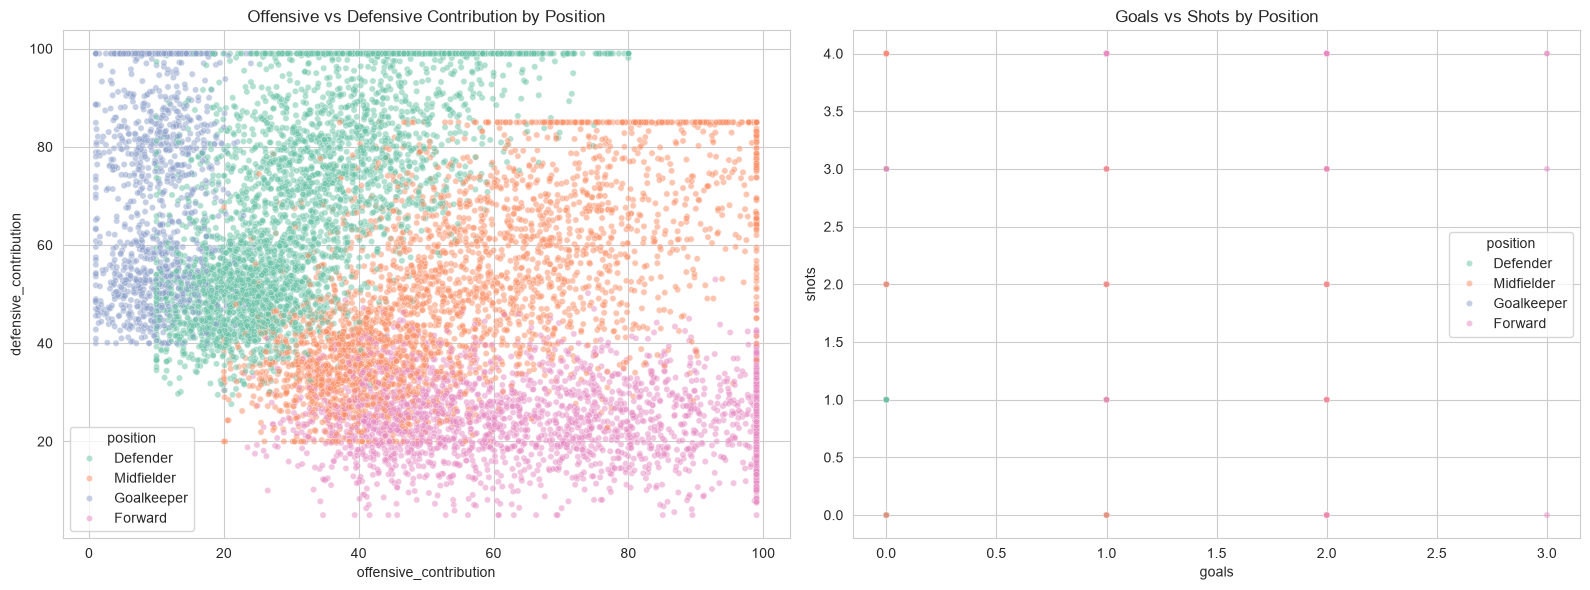

In [18]:
# Target distribution
fig, ax = plt.subplots(figsize=(8, 5))
df['position'].value_counts().plot(kind='bar', ax=ax, color=sns.color_palette('Set2'))
ax.set_title('Target Distribution — Player Position', fontsize=14)
ax.set_xlabel('Position')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print("="*35)
print("Class proportions:")
print(df['position'].value_counts(normalize=True).sort_index().round(4))
print("="*35)
# Correlation heatmap — selected key features only (not all 75 columns)
heatmap_cols = ['goals','assists','shots','shots_on_target','expected_goals_xg',
                'key_passes','pass_accuracy','tackles','interceptions','clearances',
                'saves','distance_covered_km','player_rating','performance_score',
                'offensive_contribution','defensive_contribution']

plt.figure(figsize=(12, 10))
corr_matrix = df[heatmap_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap — Key Performance Features', fontsize=14)
plt.tight_layout()
plt.show()
# Feature distributions by position — 6 discriminative features
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
box_features = ['saves','goals','clearances','key_passes',
                'offensive_contribution','defensive_contribution']
for ax, feat in zip(axes.flat, box_features):
    sns.boxplot(data=df, x='position', y=feat, ax=ax, hue='position',
                palette='Set2', legend=False)
    ax.set_title(f'{feat} by Position')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
# Distribution plots for ALL numeric features
numeric_cols = df.select_dtypes(include=np.number).columns

n = len(numeric_cols)
ncols = 8
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(24, 3 * nrows))
axes = axes.flat

for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col], bins=30, color=sns.color_palette('Set2')[0], edgecolor='white')
    ax.set_title(col, fontsize=8)
    ax.tick_params(labelsize=7)

# hide empty subplots
for ax in axes[n:]:
    ax.set_visible(False)

plt.suptitle('Feature Distributions — All Numeric Features', fontsize=16, y=1.005)
plt.tight_layout()
plt.show()
# Scatter plots showing feature-target relationships
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df, x='offensive_contribution', y='defensive_contribution',
                hue='position', palette='Set2', ax=axes[0], alpha=0.5, s=20)
axes[0].set_title('Offensive vs Defensive Contribution by Position')

sns.scatterplot(data=df, x='goals', y='shots',
                hue='position', palette='Set2', ax=axes[1], alpha=0.5, s=20)
axes[1].set_title('Goals vs Shots by Position')

plt.tight_layout()
plt.show()

---
## Section 4: Data Preprocessing

**Steps**: Handle missing values, encode, scale, split.

In [19]:
# Columns to drop
drop_cols = ['player_id','player_name','nationality','team','jersey_number',
             'club_name','match_id','match_date','stadium','city',
             'opponent_team','tournament_stage','match_result',
             'goals_team','goals_opponent']

df_model = df.drop(columns=drop_cols)

# Encode target
le = LabelEncoder()
df_model['position'] = le.fit_transform(df_model['position'])
print("="*130)
print("Position encoding:", dict(zip(le.classes_, le.transform(le.classes_))))
print("="*130)

# Binary encode preferred_foot
df_model['preferred_foot'] = df_model['preferred_foot'].map({'Left': 0, 'Right': 1})

# Separate features and target
X = df_model.drop(columns=['position'])
y = df_model['position']

# Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train class distribution:\n{y_train.value_counts(normalize=True).sort_index().round(4)}")

# Scale features — fit on train only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"\nScaled train — mean: {X_train_scaled.mean():.4f}, std: {X_train_scaled.std():.4f}")

Position encoding: {'Defender': np.int64(0), 'Forward': np.int64(1), 'Goalkeeper': np.int64(2), 'Midfielder': np.int64(3)}

Train shape: (8000, 59), Test shape: (2000, 59)
Train class distribution:
position
0    0.3491
1    0.2284
2    0.1151
3    0.3074
Name: proportion, dtype: float64

Scaled train — mean: -0.0000, std: 1.0000


---
## Section 5: Model Training

**Algorithm**: Support Vector Classifier


In [20]:
# Compare kernels (linear vs rbf) and C values on a small grid
kernels = ['linear', 'rbf']
C_values = [0.1, 1, 10]
results = []

for kernel in kernels:
    for C in C_values:
        svc = SVC(kernel=kernel, C=C, random_state=RANDOM_STATE)
        svc.fit(X_train_scaled, y_train)
        acc = accuracy_score(y_test, svc.predict(X_test_scaled))
        results.append({'kernel': kernel, 'C': C, 'accuracy': acc})
        print(f"  kernel={kernel:8s}  C={C:<5}  accuracy={acc:.4f}")

results_df = pd.DataFrame(results)
best_row = results_df.loc[results_df['accuracy'].idxmax()]
best_kernel = best_row['kernel']
best_C = best_row['C']
print(f"\nBest: kernel={best_kernel}, C={best_C}, accuracy={best_row['accuracy']:.4f}")

# Train final model with best hyperparameters
# probability=True enables predict_proba for ROC-AUC
model = SVC(kernel=best_kernel, C=best_C, probability=True, random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(f"SVC trained with kernel='{best_kernel}', C={best_C}")

  kernel=linear    C=0.1    accuracy=0.9660
  kernel=linear    C=1      accuracy=0.9670
  kernel=linear    C=10     accuracy=0.9660
  kernel=rbf       C=0.1    accuracy=0.9420
  kernel=rbf       C=1      accuracy=0.9575
  kernel=rbf       C=10     accuracy=0.9615

Best: kernel=linear, C=1.0, accuracy=0.9670
SVC trained with kernel='linear', C=1.0


---
## Section 6: Model Evaluation

**Metrics**: Accuracy, Precision, Recall, F1, Confusion Matrix.

  Support Vector Machine (SVC) — Evaluation Metrics
  Accuracy : 0.9670
  Precision: 0.9670
  Recall   : 0.9670
  F1-score : 0.9670
  ROC-AUC  : 0.9975


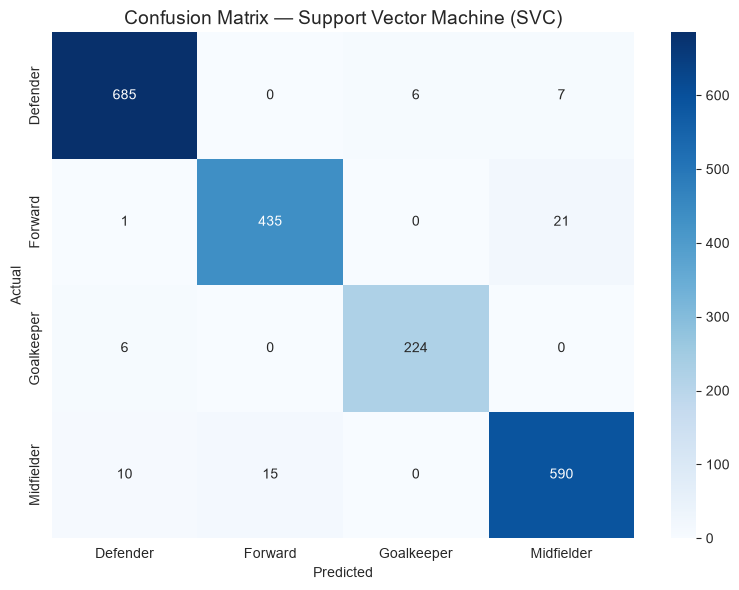

Classification Report:
              precision    recall  f1-score   support

    Defender       0.98      0.98      0.98       698
     Forward       0.97      0.95      0.96       457
  Goalkeeper       0.97      0.97      0.97       230
  Midfielder       0.95      0.96      0.96       615

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000

5-Fold CV Accuracy: 0.9578 (+/- 0.0084)
Fold scores: [0.9662 0.9662 0.9512 0.96   0.945 ]


Classification Report:
              precision    recall  f1-score   support

    Defender       0.98      0.98      0.98       698
     Forward       0.96      0.95      0.96       457
  Goalkeeper       0.98      0.98      0.98       230
  Midfielder       0.95      0.96      0.96       615

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



In [21]:
# Predictions
y_pred = model.predict(X_test_scaled)

# Get probability estimates for ROC-AUC
y_proba = model.predict_proba(X_test_scaled)

# Metrics
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall    = recall_score(y_test, y_pred, average='weighted')
f1        = f1_score(y_test, y_pred, average='weighted')
roc_auc   = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted')

print("=" * 50)
print(f"  Support Vector Machine (SVC) — Evaluation Metrics")
print("=" * 50)
print(f"  Accuracy : {accuracy:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall   : {recall:.4f}")
print(f"  F1-score : {f1:.4f}")
print(f"  ROC-AUC  : {roc_auc:.4f}")
print("=" * 50)

# Confusion Matrix 
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix — Support Vector Machine (SVC)', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

print("="*60)
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))
print("="*60)

# 5-fold cross-validation
cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"5-Fold CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
print(f"Fold scores: {cv_scores.round(4)}")

---
## Section 7: Results & Conclusions

Summary of model performance.

In [22]:
# Feature 1: combined attacking output
df['goal_contribution'] = df['goals'] + df['assists']

# Feature 2: normalised aerial duel success 
df['duel_success_rate'] = df['aerial_duels_won'] / (df['aerial_duels_won'] + df['aerial_duels_lost'] + 1)

print("="*45)
print("Engineered features — descriptive stats:")
print("="*45)
print(df[['goal_contribution','duel_success_rate']].describe().round(3))
print("="*45)
# Train final model with best hyperparameters
# probability=True enables predict_proba for ROC-AUC


Engineered features — descriptive stats:
       goal_contribution  duel_success_rate
count          10000.000          10000.000
mean               0.108              0.200
std                0.361              0.270
min                0.000              0.000
25%                0.000              0.000
50%                0.000              0.000
75%                0.000              0.500
max                4.000              0.875


SVC trained with kernel='linear', C=1.0
